<a href="https://colab.research.google.com/github/fauziihadiwijaya/Uts-deep-learning-2026/blob/main/Clustering/image_representation/image_representation_encoder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Task 3 — Image Representation & Encoder**

## Summary

1. Tools: PyTorch
2. Metode: CNN ResNet kecil, dilatih tanpa label dengan SimCLR (contrastive learning)
3. Augmentasi: rotasi bebas, skala, flip, gamma, blur, noise, standardisasi per citra
4. Baseline: PCA piksel mentah
5. Evaluasi tanpa label: invariansi, retrieval top-1, kebocoran mikroskop
6. Output: image_encoder_artifacts (format sama dengan spectrum_encoder_artifacts)

Notebook ini mengerjakan cabang **image representation dan image encoder** saja, pasangan dari notebook Spectrum Representation & Encoder. Feature fusion, jumlah cluster, metode clustering, analisis, dan cluster.csv dikerjakan di notebook Multimodal Clustering (gabungan), yang memakai artefak dari kedua notebook ini.

**Cara menjalankan (Colab, T4 GPU):** pilih Runtime → Change runtime type → T4 GPU, taruh clustering.npz dan clustering_meta.csv di DATA_DIR, lalu Runtime → Run all. Hasil training disimpan ke OUT_DIR, jadi saat dijalankan ulang model yang sudah ada langsung dimuat tanpa training lagi.

## **0. Setup Lingkungan & Hyperparameter**

Bagian ini menyiapkan pustaka, jalur input/output, random seed, dan semua hyperparameter dalam dictionary CFG. SEED dibuat sama dengan notebook spectrum encoder (42). SMOKE adalah mode uji cepat yang menjalankan seluruh notebook dengan sedikit sampel dan 1 epoch, hanya untuk memastikan kode tidak error angka yang dihasilkan pada mode ini tidak bermakna.

In [1]:
import os, sys, time, math, random, platform, warnings, json, zipfile
from pathlib import Path
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import sklearn, scipy
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from IPython.display import display
warnings.filterwarnings('ignore', category=FutureWarning)

DATA_DIR = Path(os.environ.get('DATA_DIR', '/content/drive/MyDrive/UTS_DL'))           # folder clustering.npz & clustering_meta.csv
SMOKE    = os.environ.get('SMOKE', '0') == '1'                                         # ubah ke True biar aktif

if str(DATA_DIR).startswith('/content/drive') and not Path('/content/drive/MyDrive').exists():
    from google.colab import drive
    drive.mount('/content/drive')

OUT_DIR = Path(os.environ.get('OUT_DIR', DATA_DIR / 'hasil_tugas3')) / ('smoke' if SMOKE else '')
ART_DIR = OUT_DIR / 'image_encoder_artifacts'
ART_DIR.mkdir(parents=True, exist_ok=True)

CFG = dict(
    seed=42,                                         # sama dengan notebook spectrum encoder
    emb_dim=256, proj_dim=128,                       # dimensi embedding backbone & proyeksi kontrastif
    epochs=100, batch=512, lr=1e-3, wd=1e-4,         # optimizer AdamW + warmup & cosine annealing
    temp=0.2, val_frac=0.10,                         # suhu NT-Xent, porsi data untuk memantau loss
    scale=(0.75, 1.33), gamma=(0.7, 1.4),            # augmentasi: rentang zoom & gamma
    blur=(0.0, 1.2), noise=0.04,                     # augmentasi: sigma blur & std noise
    pca_raw=64,                                      # baseline PCA piksel mentah
)
if SMOKE:
    CFG.update(epochs=1, batch=64)

dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = dev.type == 'cuda'                              # mixed precision di GPU
torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6']   # urutan warna tetap
mpl.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
                     'lines.linewidth': 1.8, 'axes.prop_cycle': mpl.cycler(color=PAL),
                     'axes.titlesize': 10, 'axes.labelsize': 9, 'legend.frameon': False, 'legend.fontsize': 8})

print('python', platform.python_version(), '| torch', torch.__version__, '| numpy', np.__version__,
      '| pandas', pd.__version__, '| sklearn', sklearn.__version__)
print('device:', torch.cuda.get_device_name(0) if dev.type == 'cuda' else 'CPU', '| out:', OUT_DIR)

Mounted at /content/drive
python 3.13.16 | torch 2.14.1+cu130 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1
device: Tesla T4 | out: /content/drive/MyDrive/UTS_DL/hasil_tugas3


## 1. Load data

Citra mikrostruktur dibaca dari array gambar di clustering.npz, sedangkan id_sampel dan mikroskop dari clustering_meta.csv. Array spektrum tidak dipakai di notebook ini. Pemeriksaan assert memastikan baris ke-i pada metadata berkorespondensi dengan indeks ke-i pada array, karena urutan ini yang menjaga embedding tetap terhubung ke id_sampel yang benar.

In [2]:
meta = pd.read_csv(DATA_DIR / 'clustering_meta.csv')
z = np.load(DATA_DIR / 'clustering.npz')
assert 'gambar' in z.files, "Array 'gambar' tidak ditemukan."
img_all = z['gambar']
assert img_all.dtype == np.uint8 and img_all.shape[1:] == (64, 64)
assert len(meta) == len(img_all)
assert (meta['indeks'].values == np.arange(len(meta))).all() and meta['id_sampel'].is_unique

if SMOKE:   # ambil sebagian kecil sampel (seed sama di kedua notebook agar id_sampel cocok)
    keep = np.sort(np.random.default_rng(0).choice(len(meta), min(400, len(meta)), replace=False))
    meta, img_all = meta.iloc[keep].reset_index(drop=True), img_all[keep]

N = len(meta)
MICS = ['M1', 'M2']
mic = (meta['mikroskop'] == 'M2').values.astype(np.int64)      # 0 = M1, 1 = M2
print('gambar', img_all.shape, img_all.dtype, f'| piksel {img_all.min()}-{img_all.max()} | sampel', N)
display(meta['mikroskop'].value_counts().rename('jumlah_sampel').to_frame())

gambar (36000, 64, 64) uint8 | piksel 0-255 | sampel 36000


,jumlah_sampel
mikroskop,
M1,21636
M2,14364


## 2. Exploration (a)

**Contoh citra per mikroskop.** Delapan belas sampel acak dari M1 (atas) dan M2 (bawah). Hal yang dicari: apakah tekstur yang sama muncul dalam orientasi berbeda (rotasi), dengan ukuran butir berbeda (skala), dengan kecerahan atau ketajaman berbeda, dan apakah kedua mikroskop menghasilkan tampilan yang berbeda untuk struktur yang mirip.

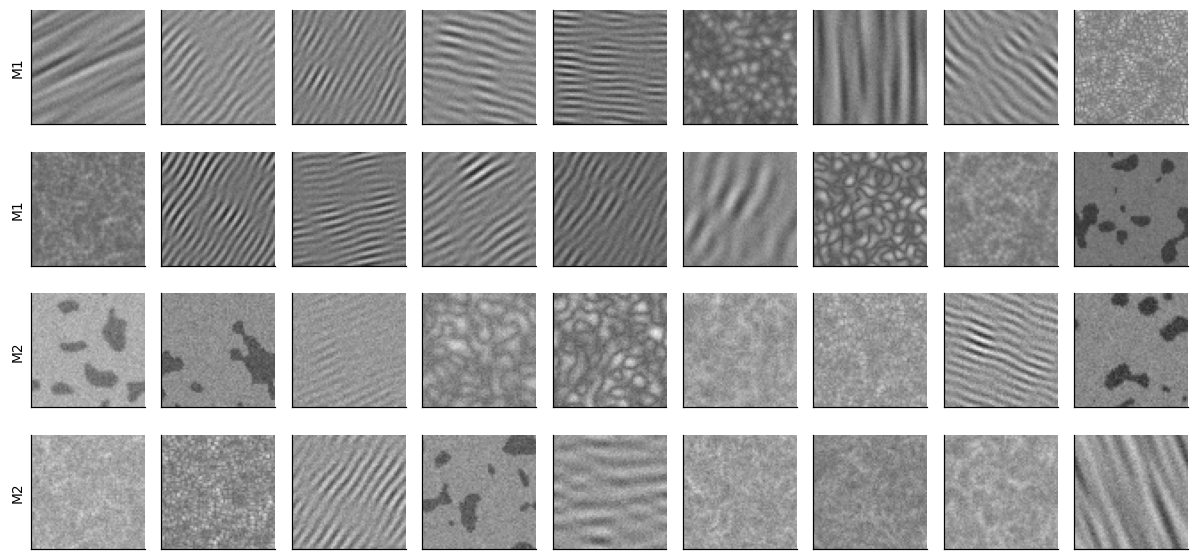

In [3]:
rng = np.random.default_rng(CFG['seed'])
fig, axes = plt.subplots(4, 9, figsize=(11, 5.4))
for r in range(4):
    pool = np.where(mic == (r >= 2))[0]
    for c, i in enumerate(rng.choice(pool, 9, replace=False)):
        ax = axes[r, c]; ax.imshow(img_all[i], cmap='gray', vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    axes[r, 0].set_ylabel(MICS[r >= 2], fontsize=9)
plt.tight_layout(); plt.show()

**Mengukur distorsi citra.** Setiap citra diringkas menjadi lima angka:
- **Brightness** dan **contrast**: rata-rata dan simpangan baku piksel.
- **Sharpness**: varians Laplacian nilai kecil berarti citra lebih blur (indikasi fokus mikroskop berbeda).
- **Orientasi dominan**: sudut dari structure tensor gradien. Kalau rotasi acak, histogram sudut akan datar dari -90° sampai 90°. Hanya citra dengan arah tekstur jelas (coherence di atas median) yang dipakai.
- **Skala tekstur**: periode rata-rata dari power spectrum (dalam piksel). Sebaran yang lebar berarti ukuran butir bervariasi, baik karena material berbeda maupun karena zoom.

Kalau distribusi M1 dan M2 berbeda pada brightness, contrast, atau sharpness, maka ada perbedaan mikroskop yang harus dinetralkan agar cluster tidak terbentuk berdasarkan alat ukur.

brightness         contrast         sharpness         coherence  \
                mean     std     mean     std      mean     std      mean   
mikroskop                                                                   
M1            0.5012  0.0473   0.0772  0.0211    0.0201  0.0229    0.4216   
M2            0.5728  0.0432   0.0780  0.0182    0.0354  0.0191    0.3113   

                  skala_px          
              std     mean     std  
mikroskop                           
M1         0.3923   7.0215  2.6568  
M2         0.3053   5.4881  1.8075

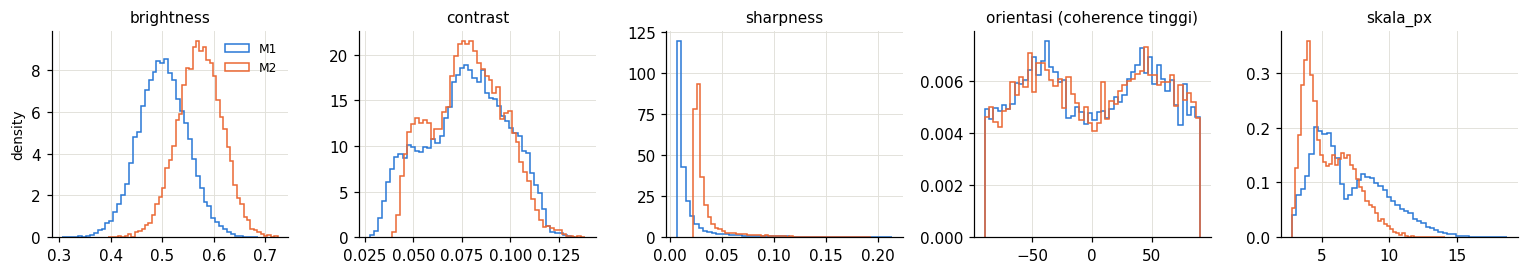

In [4]:
def image_stats(imgs, chunk=2000):
    H = imgs.shape[1]
    fy, fx = np.meshgrid(np.fft.fftfreq(H), np.fft.fftfreq(H), indexing='ij')
    fr = np.sqrt(fx ** 2 + fy ** 2); fr[0, 0] = np.inf                       # abaikan komponen DC
    out = []
    for i in range(0, len(imgs), chunk):
        x = imgs[i:i + chunk].astype(np.float32) / 255
        gy, gx = np.gradient(x, axis=(1, 2))
        jxx, jyy, jxy = (gx * gx).mean((1, 2)), (gy * gy).mean((1, 2)), (gx * gy).mean((1, 2))
        ang = 0.5 * np.degrees(np.arctan2(2 * jxy, jxx - jyy))
        coh = np.sqrt((jxx - jyy) ** 2 + 4 * jxy ** 2) / (jxx + jyy + 1e-12)
        lap = x[:, 1:-1, :-2] + x[:, 1:-1, 2:] + x[:, :-2, 1:-1] + x[:, 2:, 1:-1] - 4 * x[:, 1:-1, 1:-1]
        P = np.abs(np.fft.fft2(x - x.mean((1, 2), keepdims=True))) ** 2
        f_mean = (P * np.where(np.isinf(fr), 0, fr)).sum((1, 2)) / (P.sum((1, 2)) + 1e-12)
        out.append(np.stack([x.mean((1, 2)), x.std((1, 2)), lap.var((1, 2)), ang, coh, 1 / (f_mean + 1e-12)], 1))
    return pd.DataFrame(np.concatenate(out), columns=['brightness', 'contrast', 'sharpness', 'orientasi', 'coherence', 'skala_px'])

ist = image_stats(img_all)
ist['mikroskop'] = meta['mikroskop'].values
display(ist.groupby('mikroskop')[['brightness', 'contrast', 'sharpness', 'coherence', 'skala_px']].agg(['mean', 'std']).round(4))

fig, axes = plt.subplots(1, 5, figsize=(14, 2.6))
strong = ist['coherence'] > ist['coherence'].median()
for ax, col in zip(axes, ['brightness', 'contrast', 'sharpness', 'orientasi', 'skala_px']):
    for m, name in enumerate(MICS):
        sel = (mic == m) & (strong.values if col == 'orientasi' else True)
        ax.hist(ist[col][sel], bins=50, histtype='step', density=True, color=PAL[m], lw=1.6, label=name)
    ax.set_title(col + (' (coherence tinggi)' if col == 'orientasi' else ''))
axes[0].set_ylabel('density'); axes[0].legend()
plt.tight_layout(); plt.show()

## 3. Preprocessing & augmentasi (b)

**Standardisasi per citra.** Setiap citra dikurangi rata-ratanya dan dibagi simpangan bakunya sendiri. Langkah ini menghapus perbedaan brightness dan contrast linear sepenuhnya, termasuk yang berasal dari perbedaan mikroskop, sehingga augmentasi brightness dan contrast tidak diperlukan lagi.

**Augmentasi dan alasannya.** Contrastive learning (SimCLR) melatih encoder agar dua versi augmentasi dari citra yang sama menghasilkan embedding yang dekat, sedangkan citra lain dijauhkan. Akibatnya encoder menjadi tidak peka terhadap apa pun yang diubah oleh augmentasi.

Augmentasi yang sengaja tidak dipakai: crop kecil yang agresif dan perubahan warna, karena ukuran butir dan pola tekstur adalah informasi jenis material. Semua augmentasi dijalankan langsung di GPU per batch.

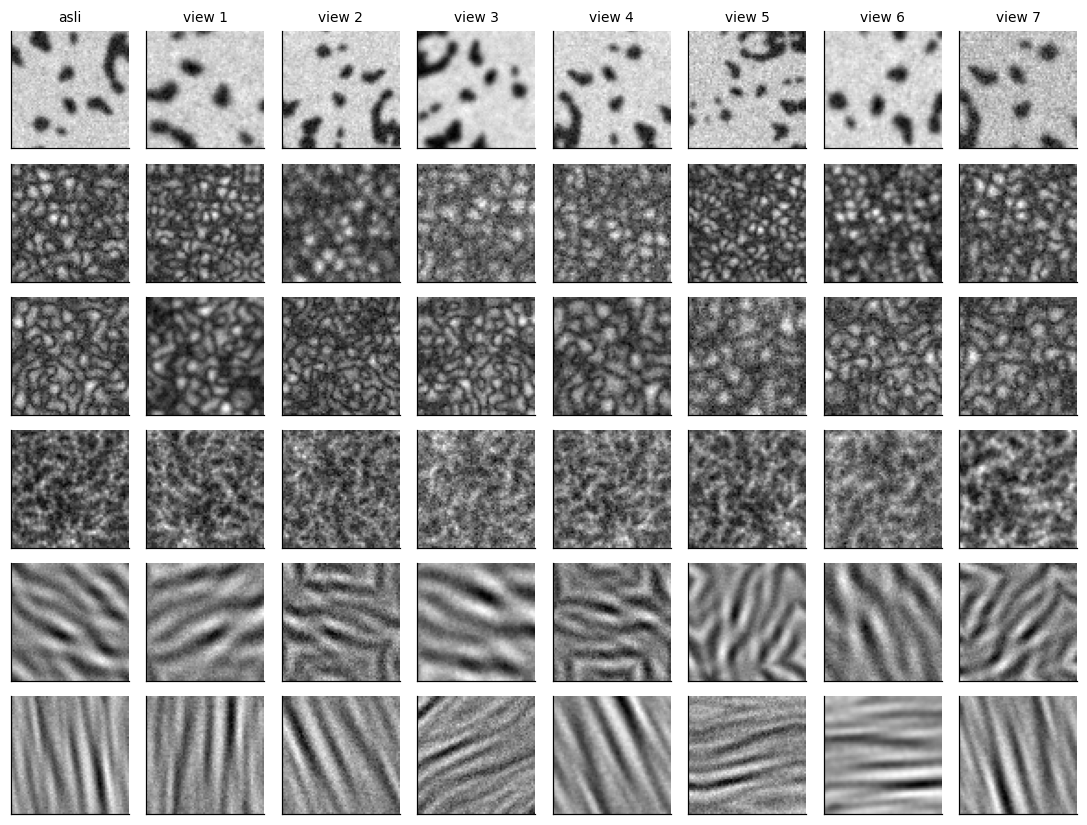

In [5]:
IMG = torch.from_numpy(img_all).to(dev)                       # uint8 (N, 64, 64) di memori GPU

def to_float(b):
    return IMG[b].float().div(255)[:, None]                  # (B, 1, 64, 64) dalam rentang 0-1

def standardize(x):
    return (x - x.mean((2, 3), keepdim=True)) / (x.std((2, 3), keepdim=True) + 1e-5)

def gaussian_blur(x, sigma, k=7):
    """Blur Gaussian dengan sigma berbeda per sampel (sigma=0 berarti tidak diubah)."""
    r = torch.arange(k, device=x.device, dtype=x.dtype) - k // 2
    w = torch.exp(-r[None] ** 2 / (2 * sigma[:, None].clamp_min(1e-3) ** 2)); w = w / w.sum(1, keepdim=True)
    B, _, H, W = x.shape
    y = x.reshape(1, B, H, W)
    y = F.conv2d(F.pad(y, (k // 2, k // 2, 0, 0), mode='reflect'), w[:, None, None, :], groups=B)
    y = F.conv2d(F.pad(y, (0, 0, k // 2, k // 2), mode='reflect'), w[:, None, :, None], groups=B)
    return y.reshape(B, 1, H, W)

def augment(x):
    """x: (B,1,64,64) rentang 0-1 -> satu view acak yang sudah distandardisasi."""
    B, d = x.shape[0], x.device
    U = lambda lo, hi: torch.empty(B, device=d).uniform_(lo, hi)
    ang = U(0, 2 * math.pi)
    s = torch.exp(U(math.log(CFG['scale'][0]), math.log(CFG['scale'][1])))
    fl = torch.where(torch.rand(B, device=d) < 0.5, -1.0, 1.0)
    cos, sin = torch.cos(ang) / s, torch.sin(ang) / s
    theta = torch.stack([torch.stack([cos * fl, -sin, U(-0.1, 0.1)], 1),
                         torch.stack([sin * fl, cos, U(-0.1, 0.1)], 1)], 1)       # rotasi + zoom + flip + geser
    x = F.grid_sample(x, F.affine_grid(theta, list(x.shape), align_corners=False),
                      mode='bilinear', padding_mode='reflection', align_corners=False)
    sig = U(*CFG['blur']) * (torch.rand(B, device=d) < 0.5)
    x = gaussian_blur(x, sig)
    x = x.clamp(1e-4, 1).pow(U(*CFG['gamma'])[:, None, None, None])
    x = x + torch.randn_like(x) * U(0, CFG['noise'])[:, None, None, None]
    return standardize(x)

set_seed(CFG['seed'])
show = torch.as_tensor(rng.choice(N, 6, replace=False), device=dev)
x0 = to_float(show)
views = [standardize(x0)] + [augment(x0) for _ in range(7)]
fig, axes = plt.subplots(6, 8, figsize=(10, 7.6))
for j, v in enumerate(views):
    for i in range(6):
        ax = axes[i, j]; ax.imshow(v[i, 0].cpu().numpy(), cmap='gray'); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    axes[0, j].set_title('asli' if j == 0 else f'view {j}', fontsize=9)
plt.tight_layout(); plt.show()

**Contoh augmentasi.** Kolom pertama adalah citra asli setelah standardisasi, tujuh kolom lainnya adalah view acak dari citra yang sama. Setiap view harus masih terlihat sebagai material yang sama. Kalau augmentasi terlalu kuat sampai tekstur tidak bisa dikenali, rentang di CFG perlu dikecilkan.

## 4. Image encoder: SimCLR (b)

**Arsitektur.** Encoder adalah CNN bergaya ResNet ringan, sama seperti image encoder di Task 1 agar kode kelompok konsisten. Satu konvolusi pada resolusi penuh, lalu tiga blok residual yang masing-masing memangkas resolusi menjadi setengahnya (64 → 32 → 16 → 8), kemudian global average pooling menghasilkan vektor 256 dimensi. Vektor inilah yang dipakai sebagai image embedding.

**Projection head.** MLP kecil (256 → 256 → 128) hanya dipakai saat training. Loss dihitung pada keluaran head, sedangkan embedding untuk clustering diambil dari backbone sebelum head, karena head cenderung membuang informasi yang tidak dibutuhkan loss kontrastif (Chen dkk., 2020).

**Loss NT-Xent.** Untuk batch berisi B citra dibuat 2B view. Bagi setiap view, pasangan view dari citra yang sama adalah positif dan 2B − 2 view lainnya adalah negatif. Loss adalah cross-entropy untuk menemukan pasangan positif di antara 2B − 1 kandidat, dengan suhu 0.2. Metrik pendamping pos_acc adalah persentase view yang tetangga terdekatnya memang pasangannya sendiri.

In [6]:
class Res(nn.Module):
    """Blok residual: dua conv-BN dan skip connection."""
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.c1, self.b1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False), nn.BatchNorm2d(cout)
        self.c2, self.b2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False), nn.BatchNorm2d(cout)
        self.skip = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        h = F.relu(self.b1(self.c1(x)))
        return F.relu(self.b2(self.c2(h)) + self.skip(x))

class ImageEncoder(nn.Module):
    def __init__(self, dim=256):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 32, 3, 1, 1, bias=False), nn.BatchNorm2d(32), nn.ReLU(),
                                 Res(32, 64, 2), Res(64, 128, 2), Res(128, dim, 2),
                                 nn.AdaptiveAvgPool2d(1), nn.Flatten())
    def forward(self, x):                                   # (B,1,64,64) -> (B,dim)
        return self.net(x)

class SimCLR(nn.Module):
    def __init__(self, dim=256, proj=128):
        super().__init__()
        self.enc = ImageEncoder(dim)
        self.head = nn.Sequential(nn.Linear(dim, dim), nn.BatchNorm1d(dim), nn.ReLU(), nn.Linear(dim, proj))
    def forward(self, x):
        return self.head(self.enc(x))

def nt_xent(z1, z2, T):
    z = F.normalize(torch.cat([z1, z2]).float(), dim=1)
    sim = z @ z.T / T
    sim.fill_diagonal_(float('-inf'))                        # view tidak dibandingkan dengan dirinya sendiri
    B = len(z1)
    tgt = torch.cat([torch.arange(B, 2 * B), torch.arange(B)]).to(z.device)   # pasangan positif
    return F.cross_entropy(sim, tgt), (sim.argmax(1) == tgt).float().mean()

net = SimCLR(CFG['emb_dim'], CFG['proj_dim']).to(dev)
print(f"parameter encoder {sum(p.numel() for p in net.enc.parameters()) / 1e6:.2f}M | head {sum(p.numel() for p in net.head.parameters()) / 1e6:.2f}M")
with torch.no_grad():
    print('embedding', tuple(net.eval().enc(views[0]).shape), '| proyeksi', tuple(net(views[0]).shape))

parameter encoder 1.21M | head 0.10M
embedding (6, 256) | proyeksi (6, 128)


### Sanity check: overfit satu batch

Sebelum training penuh, pipeline diuji pada satu batch berisi 128 citra dengan dua view tetap (augmentasi hanya dibuat sekali). Dua kriteria:
1. Loss awal mendekati ln(2B − 1) = ln(255) ≈ 5.54, yaitu tebakan acak di antara 255 kandidat.
2. Setelah 150 langkah loss turun mendekati nol dan pos_acc mencapai 100%, membuktikan loss, gradien, dan pasangan positif sudah benar.

loss awal 5.102 (ln 255 = 5.541) | loss akhir 0.9992 | pos_acc akhir 100.00%


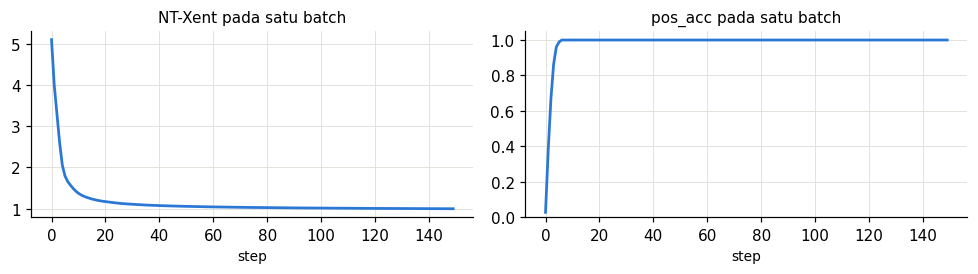

In [7]:
set_seed(CFG['seed'])
b = torch.arange(min(128, N), device=dev)
x = to_float(b); v1, v2 = augment(x), augment(x)
sn = SimCLR(CFG['emb_dim'], CFG['proj_dim']).to(dev)
opt = torch.optim.Adam(sn.parameters(), lr=1e-3)
log = []
for step in range(5 if SMOKE else 150):
    sn.train()
    loss, acc = nt_xent(sn(v1), sn(v2), CFG['temp'])
    opt.zero_grad(); loss.backward(); opt.step()
    log.append((loss.item(), acc.item()))
log = np.array(log)
print(f'loss awal {log[0, 0]:.3f} (ln {2 * len(b) - 1} = {math.log(2 * len(b) - 1):.3f}) | loss akhir {log[-1, 0]:.4f} | pos_acc akhir {log[-1, 1]:.2%}')

fig, axes = plt.subplots(1, 2, figsize=(9, 2.6))
axes[0].plot(log[:, 0]); axes[0].set_title('NT-Xent pada satu batch')
axes[1].plot(log[:, 1]); axes[1].set_title('pos_acc pada satu batch'); axes[1].set_ylim(0, 1.05)
for ax in axes: ax.set_xlabel('step')
plt.tight_layout(); plt.show()

### Training SimCLR

Data dibagi 90% untuk training dan 10% untuk memantau loss kontrastif, terstratifikasi berdasarkan mikroskop. Validasi di sini bukan untuk akurasi (tidak ada label), melainkan untuk melihat apakah encoder overfit pada citra yang dilihatnya. Validasi memakai seed augmentasi tetap agar angka antar epoch sebanding.

Optimizer AdamW dengan warmup linear 5% langkah awal lalu cosine decay, plus mixed precision. Hasil training disimpan ke OUT_DIR dan langsung dimuat jika sudah ada. Karena tidak memakai label, embedding akhir diambil dari model ini untuk seluruh sampel (training dan validasi).

train 32,400 | val 3,600
[simclr] ep   1/100  train loss 5.747 pos_acc 0.026 | val loss 5.321 pos_acc 0.062 | 10s
[simclr] ep  10/100  train loss 3.534 pos_acc 0.639 | val loss 3.616 pos_acc 0.633 | 101s
[simclr] ep  20/100  train loss 3.322 pos_acc 0.748 | val loss 3.373 pos_acc 0.744 | 200s
[simclr] ep  30/100  train loss 3.218 pos_acc 0.796 | val loss 3.286 pos_acc 0.778 | 299s
[simclr] ep  40/100  train loss 3.152 pos_acc 0.828 | val loss 3.179 pos_acc 0.827 | 398s
[simclr] ep  50/100  train loss 3.105 pos_acc 0.849 | val loss 3.137 pos_acc 0.845 | 497s
[simclr] ep  60/100  train loss 3.058 pos_acc 0.869 | val loss 3.091 pos_acc 0.858 | 596s
[simclr] ep  70/100  train loss 3.026 pos_acc 0.881 | val loss 3.044 pos_acc 0.872 | 695s
[simclr] ep  80/100  train loss 2.999 pos_acc 0.891 | val loss 3.017 pos_acc 0.883 | 794s
[simclr] ep  90/100  train loss 2.982 pos_acc 0.896 | val loss 2.995 pos_acc 0.890 | 893s
[simclr] ep 100/100  train loss 2.986 pos_acc 0.897 | val loss 2.992 pos_acc

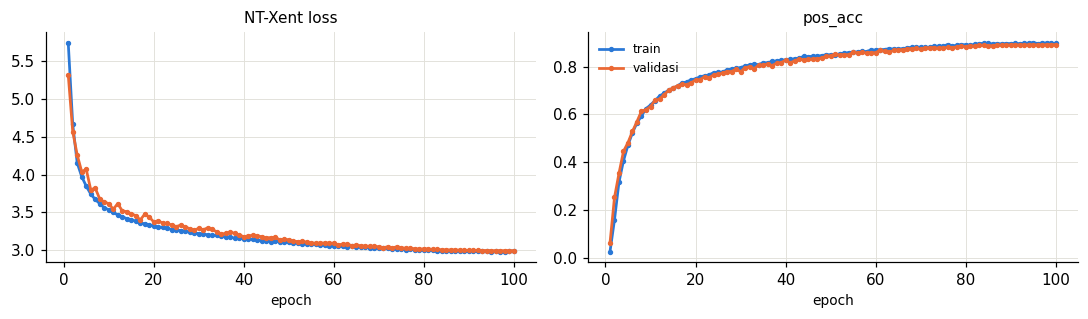

In [8]:
tr_idx, va_idx = train_test_split(np.arange(N), test_size=CFG['val_frac'], stratify=mic, random_state=CFG['seed'])
tr_idx, va_idx = np.sort(tr_idx), np.sort(va_idx)
print(f'train {len(tr_idx):,} | val {len(va_idx):,}')

@torch.no_grad()
def eval_contrastive(model, idx, bs):
    """Loss dan pos_acc pada idx dengan augmentasi berseed tetap (RNG training tidak terganggu)."""
    model.eval()
    cpu_state = torch.get_rng_state(); cuda_state = torch.cuda.get_rng_state_all() if dev.type == 'cuda' else None
    torch.manual_seed(1234)
    idx = torch.as_tensor(idx, device=dev); L, A, n = 0.0, 0.0, 0
    for i in range(0, len(idx) - 1, bs):
        b = idx[i:i + bs]
        if len(b) < 2: break
        x = to_float(b)
        with torch.autocast(dev.type, enabled=AMP):
            l, a = nt_xent(model(augment(x)), model(augment(x)), CFG['temp'])
        L += l.item() * len(b); A += a.item() * len(b); n += len(b)
    torch.set_rng_state(cpu_state)
    if cuda_state is not None: torch.cuda.set_rng_state_all(cuda_state)
    return L / n, A / n

def fit_simclr():
    E, bs = CFG['epochs'], min(CFG['batch'], len(tr_idx))
    path = OUT_DIR / f'simclr_e{E}_b{bs}.pt'
    if path.exists():
        R = torch.load(path, map_location='cpu', weights_only=False)
        print(f'[simclr] dimuat dari disk | val loss akhir {R["hist"][-1]["val_loss"]:.4f}')
        return R
    set_seed(CFG['seed'])
    model = SimCLR(CFG['emb_dim'], CFG['proj_dim']).to(dev).to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['wd'])
    steps = max(1, len(tr_idx) // bs); total = E * steps; warm = max(1, int(0.05 * total))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda t: (t + 1) / warm if t < warm else 0.5 * (1 + math.cos(math.pi * (t - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler(dev.type, enabled=AMP)
    tr_t = torch.as_tensor(tr_idx, device=dev); hist = []; t0 = time.time()
    for ep in range(1, E + 1):
        model.train(); L = A = 0.0
        perm = tr_t[torch.randperm(len(tr_t), device=dev)]
        for i in range(steps):
            x = to_float(perm[i * bs:(i + 1) * bs])
            v1, v2 = augment(x), augment(x)
            with torch.autocast(dev.type, enabled=AMP):
                loss, acc = nt_xent(model(v1), model(v2), CFG['temp'])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            L += loss.item(); A += acc.item()
        vl, va = eval_contrastive(model, va_idx, bs)
        hist.append(dict(epoch=ep, train_loss=L / steps, train_acc=A / steps, val_loss=vl, val_acc=va))
        if ep % 10 == 0 or ep in (1, E):
            print(f'[simclr] ep {ep:3d}/{E}  train loss {L / steps:.3f} pos_acc {A / steps:.3f} | val loss {vl:.3f} pos_acc {va:.3f} | {time.time() - t0:.0f}s')
    R = dict(hist=hist, state={k: v.cpu() for k, v in model.state_dict().items()}, secs=time.time() - t0, epochs=E, batch=bs)
    torch.save(R, path)
    return R

SIM = fit_simclr()
model = SimCLR(CFG['emb_dim'], CFG['proj_dim']); model.load_state_dict(SIM['state'])
model = model.to(dev).eval()
encoder = model.enc

h = pd.DataFrame(SIM['hist'])
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, a, b_, t in [(axes[0], 'train_loss', 'val_loss', 'NT-Xent loss'), (axes[1], 'train_acc', 'val_acc', 'pos_acc')]:
    ax.plot(h['epoch'], h[a], color=PAL[0], marker='o', ms=2.5, label='train')
    ax.plot(h['epoch'], h[b_], color=PAL[1], marker='o', ms=2.5, label='validasi')
    ax.set_title(t); ax.set_xlabel('epoch')
axes[1].legend(); plt.tight_layout(); plt.show()

**Learning curve.** Loss validasi yang ikut turun bersama loss training berarti encoder mempelajari pola umum, bukan menghafal citra training. Kalau loss validasi naik sementara loss training terus turun, encoder mulai overfit dan jumlah epoch perlu dikurangi. pos_acc validasi yang tinggi menunjukkan encoder mampu mengenali citra yang sama meskipun dirotasi, di-zoom, dan di-blur.

### Ekstraksi embedding

Embedding diambil dari backbone (256 dimensi), dengan test-time augmentation berupa 8 transformasi dihedral (4 rotasi 90° × flip). Embedding akhir adalah rata-rata kedelapannya, sehingga invariansi terhadap rotasi dan flip dijamin secara eksplisit, bukan hanya dipelajari. Urutan baris sama dengan urutan metadata.

In [9]:
@torch.no_grad()
def embed_tensor(enc, x_std, tta=True):
    """x_std: citra (B,1,64,64) yang sudah distandardisasi -> embedding (B, dim)."""
    enc.eval(); views = []
    for k in (range(4) if tta else [0]):
        r = torch.rot90(x_std, k, (2, 3))
        views += [r, r.flip(3)] if tta else [r]
    f = 0
    for v in views:
        with torch.autocast(dev.type, enabled=AMP):
            f = f + enc(v).float()
    return f / len(views)

@torch.no_grad()
def embed_images(enc, idx, tta=True, bs=1024):
    idx = torch.as_tensor(idx, device=dev)
    return torch.cat([embed_tensor(enc, standardize(to_float(idx[i:i + bs])), tta).cpu()
                      for i in range(0, len(idx), bs)]).numpy()

E_img = embed_images(encoder, np.arange(N))
print('image embedding', E_img.shape, '| NaN', int(np.isnan(E_img).sum()), '| dimensi mati (std=0)', int((E_img.std(0) < 1e-6).sum()))

image embedding (36000, 256) | NaN 0 | dimensi mati (std=0) 0


## 5. Evaluasi representasi tanpa label (b)

Karena label material tidak tersedia, kualitas embedding dinilai dengan tiga uji yang bisa dihitung tanpa label, dan dibandingkan dengan baseline klasik **PCA 64 komponen pada piksel mentah** (yang juga sudah distandardisasi per citra):
- **Invariansi**: 1000 citra dibandingkan dengan versi terdistorsinya (rotasi, zoom, gamma, blur, noise acak). pos_cos adalah kemiripan kosinus citra dengan versi terdistorsinya, neg_cos dengan citra lain secara acak. Representasi yang baik punya selisih (gap) besar.
- **Retrieval top-1**: persentase versi terdistorsi yang tetangga terdekatnya di antara 1000 citra asli adalah citranya sendiri.
- **Kebocoran mikroskop**: balanced accuracy regresi logistik untuk menebak mikroskop dari embedding (5-fold). Nilai 0.5 berarti embedding tidak membawa informasi mikroskop. Nilai tinggi berarti cluster berisiko terbentuk berdasarkan alat, bukan material. Catatan: kalau proporsi material memang berbeda antar mikroskop, sebagian kebocoran ini sah.

In [10]:
def raw_pixels(idx, bs=4000):
    idx = torch.as_tensor(idx, device=dev)
    return np.concatenate([standardize(to_float(idx[i:i + bs])).reshape(len(idx[i:i + bs]), -1).cpu().numpy()
                           for i in range(0, len(idx), bs)])

sub_fit = np.sort(np.random.default_rng(CFG['seed']).choice(N, min(10000, N), replace=False))
pca_raw = PCA(min(CFG['pca_raw'], len(sub_fit)), svd_solver='randomized', random_state=CFG['seed']).fit(raw_pixels(sub_fit))
E_pca = np.concatenate([pca_raw.transform(raw_pixels(np.arange(i, min(i + 4000, N)))) for i in range(0, N, 4000)]).astype(np.float32)
print('PCA piksel', E_pca.shape, f'| varians terjelaskan {pca_raw.explained_variance_ratio_.sum():.1%}')

def representation_report(name, emb, f_distort):
    sc = StandardScaler().fit(emb)
    e0 = sc.transform(emb[inv_idx]); e1 = sc.transform(f_distort)
    e0 /= np.linalg.norm(e0, axis=1, keepdims=True); e1 /= np.linalg.norm(e1, axis=1, keepdims=True)
    pos = (e0 * e1).sum(1).mean(); neg = (e0 * e0[np.roll(np.arange(len(e0)), 1)]).sum(1).mean()
    top1 = ((e1 @ e0.T).argmax(1) == np.arange(len(e0))).mean()
    sub = np.random.default_rng(1).choice(N, min(10000, N), replace=False)
    cv = StratifiedKFold(5, shuffle=True, random_state=0)
    pred = cross_val_predict(LogisticRegression(max_iter=2000), StandardScaler().fit_transform(emb[sub]), mic[sub], cv=cv)
    return dict(representasi=name, dim=emb.shape[1], pos_cos=pos, neg_cos=neg, gap=pos - neg, retrieval_top1=top1,
                bocor_mikroskop=balanced_accuracy_score(mic[sub], pred))

inv_idx = np.sort(np.random.default_rng(2).choice(N, min(1000, N), replace=False))
set_seed(7)
x_aug = augment(to_float(torch.as_tensor(inv_idx, device=dev)))                        # versi terdistorsi
f_sim = torch.cat([embed_tensor(encoder, x_aug[i:i + 500]) for i in range(0, len(x_aug), 500)]).cpu().numpy()
f_pca = pca_raw.transform(x_aug.reshape(len(x_aug), -1).cpu().numpy())

tab_rep = pd.DataFrame([representation_report('PCA piksel (baseline)', E_pca, f_pca),
                        representation_report('SimCLR (deep)', E_img, f_sim)]).set_index('representasi')
display(tab_rep.round(4))

PCA piksel (36000, 64) | varians terjelaskan 20.9%


,dim,pos_cos,neg_cos,gap,retrieval_top1,bocor_mikroskop
representasi,,,,,,
PCA piksel (baseline),64,0.0345,-0.0100,0.0444,0.019,0.4982
SimCLR (deep),256,0.8729,0.0022,0.8707,0.663,0.8671


**Cara membaca tabel.** SimCLR seharusnya unggul jauh pada gap dan retrieval_top1, karena PCA piksel sangat sensitif terhadap rotasi: citra yang sama setelah diputar memiliki vektor piksel yang hampir tidak berkorelasi. Kolom bocor_mikroskop yang lebih rendah pada SimCLR menunjukkan augmentasi gamma dan blur berhasil menetralkan perbedaan alat.

## 6. Ekspor image embedding

Format file disamakan dengan artefak notebook spectrum encoder agar integrasi langsung jalan:

| Spectrum encoder | Image encoder |
| --- | --- |
| spectrum_embeddings.csv | image_embeddings.csv.gz |
| spectrum_embeddings.npy | image_embeddings.npy |
| spectrum_sample_ids.npy | image_sample_ids.npy |
| spectrum_autoencoder_state_dict.pt | image_encoder_state_dict.pt |
| spectrum_encoder_config.json | image_encoder_config.json |

Kolomnya sama: indeks, id_sampel, mikroskop, lalu image_emb_000 sampai image_emb_255. CSV dikompres (gz) karena 256 kolom untuk 36.000 sampel berukuran sekitar 80 MB jika tidak dikompres pandas membaca file .csv.gz secara langsung. Kunci penggabungan dengan spektrum tetap id_sampel, bukan urutan baris.

In [11]:
emb_df = pd.DataFrame({'indeks': meta['indeks'].values, 'id_sampel': meta['id_sampel'].astype(str).values,
                       'mikroskop': meta['mikroskop'].astype(str).values})
emb_df = pd.concat([emb_df, pd.DataFrame(E_img, columns=[f'image_emb_{j:03d}' for j in range(E_img.shape[1])])], axis=1)
emb_df.to_csv(ART_DIR / 'image_embeddings.csv.gz', index=False, float_format='%.5f')
np.save(ART_DIR / 'image_embeddings.npy', E_img.astype(np.float32))
np.save(ART_DIR / 'image_sample_ids.npy', meta['id_sampel'].astype(str).values)
torch.save(encoder.state_dict(), ART_DIR / 'image_encoder_state_dict.pt')

config = {
    'task': 'Task 3 - Image Representation and Encoder',
    'method': 'SimCLR (NT-Xent) dengan CNN ResNet kecil, embedding dari backbone + TTA dihedral 8 arah',
    'n_samples': int(N), 'embedding_dim': int(E_img.shape[1]),
    'epochs': int(SIM['epochs']), 'batch_size': int(SIM['batch']), 'learning_rate': CFG['lr'], 'weight_decay': CFG['wd'],
    'temperature': CFG['temp'], 'seed': CFG['seed'],
    'augmentations': {'rotation_deg': [0, 360], 'flip': True, 'scale': list(CFG['scale']), 'gamma': list(CFG['gamma']),
                      'blur_sigma': list(CFG['blur']), 'noise_std': CFG['noise'], 'per_image_standardization': True},
    'final_val_loss': float(SIM['hist'][-1]['val_loss']), 'final_val_pos_acc': float(SIM['hist'][-1]['val_acc']),
    'representation_check': tab_rep.round(4).reset_index().to_dict(orient='records'),
    'torch': torch.__version__,
}
with open(ART_DIR / 'image_encoder_config.json', 'w') as f:
    json.dump(config, f, indent=2)

with zipfile.ZipFile(OUT_DIR / 'image_encoder_artifacts.zip', 'w', zipfile.ZIP_DEFLATED) as zf:
    for p in sorted(ART_DIR.iterdir()):
        zf.write(p, arcname=p.name)
print('artefak tersimpan di', ART_DIR)
for p in sorted(ART_DIR.iterdir()):
    print(f'- {p.name:34s} {p.stat().st_size / 1e6:7.2f} MB')

artefak tersimpan di /content/drive/MyDrive/UTS_DL/hasil_tugas3/image_encoder_artifacts
- image_embeddings.csv.gz              26.77 MB
- image_embeddings.npy                 36.86 MB
- image_encoder_config.json             0.00 MB
- image_encoder_state_dict.pt           4.86 MB
- image_sample_ids.npy                  0.36 MB


## 7. Ringkasan & reproduksi

Cell ini memuat ulang bobot image encoder dari disk, menghitung ulang embedding 256 sampel pertama, lalu membandingkannya dengan embedding yang tersimpan. Selisih nol berarti embedding dapat direproduksi dari bobot yang disimpan, dan cell ini bisa dipakai saat sesi reproduksi pada ujian lisan.

In [12]:
enc2 = ImageEncoder(CFG['emb_dim'])
enc2.load_state_dict(torch.load(ART_DIR / 'image_encoder_state_dict.pt', map_location='cpu'))
enc2 = enc2.to(dev).eval()
n_chk = min(256, N)
again = embed_images(enc2, np.arange(n_chk))
saved = np.load(ART_DIR / 'image_embeddings.npy')[:n_chk]
print(f'reproduksi embedding {n_chk} sampel pertama | selisih absolut maksimum {np.abs(again - saved).max():.2e}')
print(f"val loss akhir {SIM['hist'][-1]['val_loss']:.4f} | val pos_acc akhir {SIM['hist'][-1]['val_acc']:.4f}")
display(tab_rep.round(4))

reproduksi embedding 256 sampel pertama | selisih absolut maksimum 1.22e-04
val loss akhir 2.9919 | val pos_acc akhir 0.8915


,dim,pos_cos,neg_cos,gap,retrieval_top1,bocor_mikroskop
representasi,,,,,,
PCA piksel (baseline),64,0.0345,-0.0100,0.0444,0.019,0.4982
SimCLR (deep),256,0.8729,0.0022,0.8707,0.663,0.8671


**interpretasi:**
1. Loss kontrastif yang rendah dan retrieval yang tinggi menunjukkan embedding tahan terhadap distorsi, bukan jaminan cluster material yang terbentuk akan baik.
2. Mikroskop hanya dipakai untuk stratifikasi split dan uji kebocoran, bukan sebagai label training.
3. Belum ada klaim jumlah cluster atau kualitas cluster di notebook ini keduanya diuji di notebook gabungan setelah digabung dengan spectrum embedding.